# Validation
# Setup
Running this notebook demonstrates the capabilities of our models.

**In the validation_config.yaml change the "model" variable at the top for the model you wish to evaluate**

## Imports

In [1]:
#For some reason the adapterDETR model import breaks if you don't do it first
import sys
import os
#Set parent path to the root of the repo, to be able to import models
parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, parent_dir)
from models.adapterDETR import AdapterDetr

from validation.validation_functions import eval_model, show_image_prediction
from models.adapterDETR import AdapterDetr
from data.dataloader import get_dataloader

from hydra.utils import instantiate

## Config

In [2]:
from omegaconf import OmegaConf
config = OmegaConf.load("validation_config.yaml")

## Dataloader
The dataloader loads in both imagedata and their embeddings, both can be used

I also create a subset dataset to not pass all of it through the models

In [3]:
dataset, _ = get_dataloader(config)

import torch
from torch.utils.data import Subset, DataLoader
dataloader = torch.utils.data.DataLoader(dataset, batch_size=config.data.batch_size, shuffle=False)

## TEMPORARY.
# Create a subset of the data to not overload memory
subset_dataset = torch.utils.data.Subset(dataloader.dataset, range(50))

INFO:root:Loading images from /home/veski/.cache/huggingface/hub/datasets--JierunChen--Ref-L4/snapshots/d62c4f4e5f3a639b34adab34e5c8ffeb39f168c1/images.tar.gz


Downloaded images.tar.gz to /home/veski/.cache/huggingface/hub/datasets--JierunChen--Ref-L4/snapshots/d62c4f4e5f3a639b34adab34e5c8ffeb39f168c1/images.tar.gz


100%|██████████████████████████████████████████████████████| 9735/9735 [00:12<00:00, 758.57it/s]


## Model

In [4]:
if config.model=='orgDETR':
    model = instantiate(config.org_detr)
    checkpoint_dir = config.train.org_checkpoint_dir
    resume_checkpoint_dir = config.train.org_resume_checkpoint_dir
    print(f"Loading model from {checkpoint_dir}")
elif config.model=='adapter_detr':  
    model = instantiate(config.adapter_detr)
    checkpoint_dir = config.train.checkpoint_dir
    resume_checkpoint_dir = config.train.resume_checkpoint_dir
    print(f"Loading model from {checkpoint_dir}")

Initialized SimpleAdapter: Input Dim=512, Output Dim=256, Seq Len=197
Loading model and processor from facebook/detr-resnet-50...


INFO:timm.models._builder:Loading pretrained weights from Hugging Face hub (timm/resnet50.a1_in1k)
INFO:timm.models._hub:[timm/resnet50.a1_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
INFO:timm.models._builder:Missing keys (fc.weight, fc.bias) discovered while loading pretrained weights. This is expected if model is being adapted.
Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. i

Froze DETR decoder parameters
DETR prediction heads frozen.
AdapterDetrModel initialized.
Loading model from ./checkpoints/rq1-image-only


# Evaluation

## Quantitative

Note the parameter with_images. If the model you loaded in the last step expects images as input, then put it to True

In [6]:
avg_val_loss, evaluation_results = eval_model(config,model,subset_dataset, 0.1, with_images=False)

In [7]:
print(f"Average val loss: {avg_val_loss}")
print()
for metric in evaluation_results:
    print(metric + ": " + str(evaluation_results[metric]))

Average val loss: 13.389030971527099

case1_gt_match_pred_class_box_overlap: 0
case2_overlap_right_class_not_hungarian_match: 0
case3_overlap_wrong_class: 8
case4_right_class_no_overlap: 1
total_evaluated_gt_objects: 50


## Qualitative
Note the parameter with_images. If the model you loaded in the last step expects images as input, then put it to True

This part takes an image filename, passes its embeddings (or image itself) through the model and outputs what label was most popular,
* all bounding boxes (if all_boxes = True)
* or correct ones (if all_boxes = False) or the closest box if no box overlaps or no prediction guessed the class

NB! Replace the images_path variable with wherever your Ref-L4 images.tar.gz file is located

In [44]:
# Print some filenames for usage
c = 0
for image, data in dataloader:
    print(data['file_name'][0])
    print(data['caption'][0])
    print(data['bbox'][0])
    print("--------------")  
    c += 1
    if c == 5:
        break

objects365_v2_00922765.jpg
Within the central picture frame of the three, an antique camera is present.
tensor([580.6163, 179.4965,  93.5992, 112.1014])
--------------
objects365_v1_00546894.jpg
A laundry appliance situated under a wall-mounted mirror.
tensor([135.5622, 194.3109,  74.9430, 114.7358])
--------------
objects365_v1_00546894.jpg
The white washing machine in the room corner, near the entrance to the bathroom with the door ajar.
tensor([135.5622, 194.3109,  74.9430, 114.7358])
--------------
objects365_v1_00546894.jpg
The white washing machine situated in the far left corner of the room, next to the terracotta-tiled section.
tensor([135.5622, 194.3109,  74.9430, 114.7358])
--------------
objects365_v2_01670956.jpg
The elevated white air conditioner on the left, placed above another comparable unit, both situated below the red shop sign featuring Chinese characters.
tensor([ 751.8032, 1219.0273,  361.6143,  353.4878])
--------------


Successfully opened ../Ref-L4/images.tar.gz
Passing chosen datapoint through model
######################################
Most predicted label: 329 — 95 times, avg confidence: 0.03


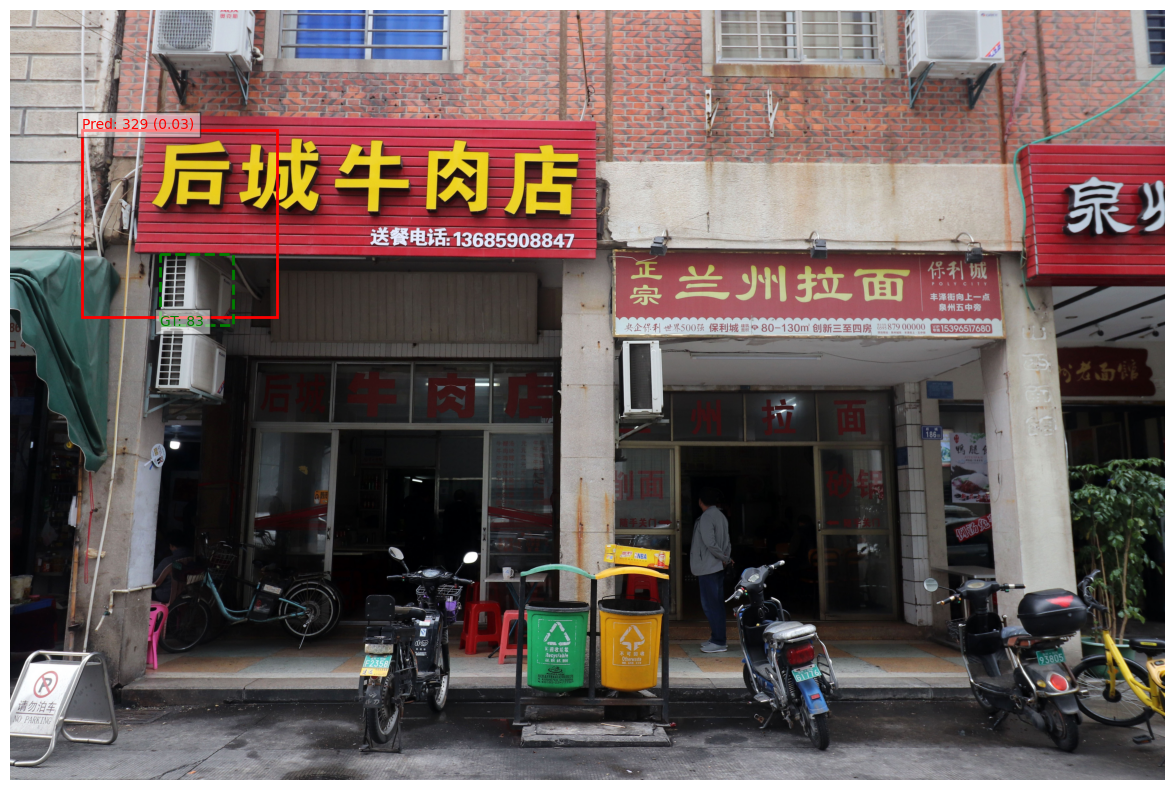

In [8]:
images_path = "../Ref-L4/images.tar.gz" 

show_image_prediction(config,
                      model,                        #
                      subset_dataset,               # Dataset to search for the image
                      0.1,                          # Iou score to consider outputting the box
                      'objects365_v2_01670956.jpg', # Image filename
                      images_path,
                      with_images = False,          # Whether the input to the model is supposed to be images
                      all_boxes = False)            # Whether to output all bounding boxes or only correctly predicted classes and overlapping ones